In [1]:
import zipfile, os, glob, json
import pandas as pd
import numpy as np

ZIP_DIR = "vmr_kaggle"          # folder containing your .zip files
EXTRACT_ROOT = "extracted_vmr_kaggle"      # where everything gets unzipped to

os.makedirs(EXTRACT_ROOT, exist_ok=True)

zip_paths = glob.glob(os.path.join(ZIP_DIR, "*.zip"))
print(f"Found {len(zip_paths)} zip files:")
for zp in zip_paths:
    print(" -", os.path.basename(zp))

for zp in zip_paths:
    name = os.path.splitext(os.path.basename(zp))[0].replace(" ", "_")
    out_dir = os.path.join(EXTRACT_ROOT, name)
    os.makedirs(out_dir, exist_ok=True)
    with zipfile.ZipFile(zp, "r") as zf:
        zf.extractall(out_dir)
    print(f"Unzipped -> {out_dir}")

Found 7 zip files:
 - freckll_profiles_acct3_checkpoint_100.zip
 - freckll_profiles_acct2_remaining_after_200.zip
 - freckll_profiles_acct3_paused_at_236.zip
 - freckll_profiles 2.zip
 - freckll_profiles_acct2_checkpoint_200.zip
 - freckll_profiles_acct1_checkpoint_100.zip
 - freckll_profiles_acct2_checkpoint_100.zip
Unzipped -> extracted_vmr_kaggle/freckll_profiles_acct3_checkpoint_100
Unzipped -> extracted_vmr_kaggle/freckll_profiles_acct2_remaining_after_200
Unzipped -> extracted_vmr_kaggle/freckll_profiles_acct3_paused_at_236
Unzipped -> extracted_vmr_kaggle/freckll_profiles_2
Unzipped -> extracted_vmr_kaggle/freckll_profiles_acct2_checkpoint_200
Unzipped -> extracted_vmr_kaggle/freckll_profiles_acct1_checkpoint_100
Unzipped -> extracted_vmr_kaggle/freckll_profiles_acct2_checkpoint_100


In [3]:
npz_files = glob.glob(os.path.join(EXTRACT_ROOT, "**", "*.npz"), recursive=True)
params_files = glob.glob(os.path.join(EXTRACT_ROOT, "**", "params_checkpoint.json"), recursive=True)

print(f"Total .npz profile files found: {len(npz_files)}")
print(f"Total params.json files found: {len(params_files)}")
for p in params_files:
    print(" -", p)

Total .npz profile files found: 746
Total params.json files found: 7
 - extracted_vmr_kaggle/freckll_profiles_acct2_checkpoint_100/freckll_profiles/params_checkpoint.json
 - extracted_vmr_kaggle/freckll_profiles_2/freckll_profiles/params_checkpoint.json
 - extracted_vmr_kaggle/freckll_profiles_acct3_checkpoint_100/freckll_profiles/params_checkpoint.json
 - extracted_vmr_kaggle/freckll_profiles_acct2_checkpoint_200/freckll_profiles/params_checkpoint.json
 - extracted_vmr_kaggle/freckll_profiles_acct1_checkpoint_100/freckll_profiles/params_checkpoint.json
 - extracted_vmr_kaggle/freckll_profiles_acct3_paused_at_236/freckll_profiles/params_checkpoint.json
 - extracted_vmr_kaggle/freckll_profiles_acct2_remaining_after_200/freckll_profiles/params_checkpoint.json


In [4]:
def extract_index(fname):
    base = os.path.basename(fname).replace(".npz", "")
    digits = "".join(ch for ch in base if ch.isdigit())
    return int(digits[-4:]) if digits else None

rows = []
for npz_path in npz_files:
    batch = npz_path.split(os.sep)[1]   # e.g. "freckll_profiles_acct1_checkpoint_100"
    idx = extract_index(npz_path)
    rows.append({"batch": batch, "index": idx, "path": npz_path})

df = pd.DataFrame(rows)
print(df.shape)
df.head()

(746, 3)


,batch,index,path
0,freckll_profiles_acct2_checkpoint_100,98,extracted_vmr_kaggle/freckll_profiles_acct2_ch...
1,freckll_profiles_acct2_checkpoint_100,67,extracted_vmr_kaggle/freckll_profiles_acct2_ch...
2,freckll_profiles_acct2_checkpoint_100,66,extracted_vmr_kaggle/freckll_profiles_acct2_ch...
3,freckll_profiles_acct2_checkpoint_100,72,extracted_vmr_kaggle/freckll_profiles_acct2_ch...
4,freckll_profiles_acct2_checkpoint_100,99,extracted_vmr_kaggle/freckll_profiles_acct2_ch...


In [5]:
param_lookup = {}  # batch -> dict of index -> params

for pf in params_files:
    batch = pf.split(os.sep)[1]
    with open(pf) as f:
        p = json.load(f)
    param_lookup[batch] = p

def get_params_for_row(row):
    batch, idx = row["batch"], row["index"]
    if batch not in param_lookup or idx is None:
        return pd.Series({"T": None, "Rp_Rj": None, "Mp_Mj": None, "Rstar_Rs": None, "log_Kzz": None})
    p = param_lookup[batch]
    try:
        return pd.Series({
            "T": p["T"][idx],
            "Rp_Rj": p["Rp_Rj"][idx],
            "Mp_Mj": p["Mp_Mj"][idx],
            "Rstar_Rs": p["Rstar_Rs"][idx],
            "log_Kzz": p["log_Kzz"][idx],
        })
    except (IndexError, KeyError):
        return pd.Series({"T": None, "Rp_Rj": None, "Mp_Mj": None, "Rstar_Rs": None, "log_Kzz": None})

param_cols = df.apply(get_params_for_row, axis=1)
df = pd.concat([df, param_cols], axis=1)
df.head()

,batch,index,path,T,Rp_Rj,Mp_Mj,Rstar_Rs,log_Kzz
0,freckll_profiles_acct2_checkpoint_100,98,extracted_vmr_kaggle/freckll_profiles_acct2_ch...,840.954267,1.344595,7.443698,0.905703,6.641810
1,freckll_profiles_acct2_checkpoint_100,67,extracted_vmr_kaggle/freckll_profiles_acct2_ch...,591.357930,1.901298,1.635848,1.143195,4.250487
2,freckll_profiles_acct2_checkpoint_100,66,extracted_vmr_kaggle/freckll_profiles_acct2_ch...,1213.248562,1.214805,1.771075,1.122038,4.140118
3,freckll_profiles_acct2_checkpoint_100,72,extracted_vmr_kaggle/freckll_profiles_acct2_ch...,1019.489505,1.202510,11.711646,1.424904,10.073632
4,freckll_profiles_acct2_checkpoint_100,99,extracted_vmr_kaggle/freckll_profiles_acct2_ch...,2263.304471,0.663275,5.398422,1.987718,7.218528


In [6]:
# Extract account label from batch name (acct1 / acct2 / acct3)
import re

def get_account(batch_name):
    m = re.search(r"acct(\d)", batch_name)
    return f"acct{m.group(1)}" if m else "unknown"

df["account"] = df["batch"].apply(get_account)

print("Files per account:")
print(df.groupby("account").size())
print()

# Within-account duplicate check: same index saved more than once
# across that account's own checkpoint/remaining zips
dupe_within_account = df.duplicated(subset=["account", "index"]).sum()
print(f"Duplicate (account, index) pairs (within-account overlap): {dupe_within_account}")

if dupe_within_account > 0:
    dupes = df[df.duplicated(subset=["account", "index"], keep=False)].sort_values(["account", "index"])
    print("\nDuplicated rows:")
    print(dupes[["account", "batch", "index", "path"]])

# Drop within-account dupes, keep first occurrence
df_dedup = df.drop_duplicates(subset=["account", "index"], keep="first")

print(f"\nTotal raw files:              {len(df)}")
print(f"After within-account dedup:   {len(df_dedup)}")
print()
print("Unique profiles per account (after dedup):")
print(df_dedup.groupby("account").size())
print(f"\nGRAND TOTAL unique VMR profiles: {len(df_dedup)}")

Files per account:
account
acct1       86
acct2      278
acct3      290
unknown     92
dtype: int64

Duplicate (account, index) pairs (within-account overlap): 183

Duplicated rows:
     account                                  batch  index  \
497    acct1  freckll_profiles_acct1_checkpoint_100      0   
503    acct1  freckll_profiles_acct1_checkpoint_100      0   
492    acct1  freckll_profiles_acct1_checkpoint_100      1   
498    acct1  freckll_profiles_acct1_checkpoint_100      1   
486    acct1  freckll_profiles_acct1_checkpoint_100      2   
..       ...                                    ...    ...   
144  unknown                     freckll_profiles_2      1   
132  unknown                     freckll_profiles_2      2   
151  unknown                     freckll_profiles_2      2   
137  unknown                     freckll_profiles_2      3   
152  unknown                     freckll_profiles_2      3   

                                                  path  
497  extracted_v

In [7]:
def profile_signature(npz_path):
    d = np.load(npz_path)
    arr = np.concatenate([d[k] for k in ["h2o", "ch4", "co", "co2", "nh3"]])
    return hash(arr.tobytes())

df_dedup["sig"] = df_dedup["path"].apply(profile_signature)

# Within-account content dupes (should be ~0 if index-dedup worked)
dupe_content_within = df_dedup.duplicated(subset=["account", "sig"]).sum()
print(f"Remaining within-account content duplicates: {dupe_content_within}")

# Cross-account content collisions would be a red flag (near-impossible with different seeds,
# but different physical params CAN occasionally converge to near-identical VMR profiles —
# this checks exact match only, not similarity)
dupe_content_cross = df_dedup.duplicated(subset=["sig"]).sum()
print(f"Cross-account exact content duplicates: {dupe_content_cross}")

print(f"\nFinal truly-unique VMR profile count: {df_dedup['sig'].nunique()}")

Remaining within-account content duplicates: 0
Cross-account exact content duplicates: 82

Final truly-unique VMR profile count: 481


In [8]:
def profile_signature(npz_path):
    d = np.load(npz_path)
    arr = np.concatenate([d[k] for k in ["h2o", "ch4", "co", "co2", "nh3"]])
    return hash(arr.tobytes())

df_dedup["sig"] = df_dedup["path"].apply(profile_signature)

dupe_content_within = df_dedup.duplicated(subset=["account", "sig"]).sum()
print(f"Remaining within-account content duplicates: {dupe_content_within}")

dupe_content_cross = df_dedup.duplicated(subset=["sig"]).sum()
print(f"Cross-account exact content duplicates: {dupe_content_cross}")

Remaining within-account content duplicates: 0
Cross-account exact content duplicates: 82


In [9]:
# Isolate just the duplicated (account, index) rows — both copies, not deduped
dupe_rows = df[df.duplicated(subset=["account", "index"], keep=False)].sort_values(["account", "index"])

def profile_signature(npz_path):
    d = np.load(npz_path)
    arr = np.concatenate([d[k] for k in ["h2o", "ch4", "co", "co2", "nh3"]])
    return arr.tobytes()  # raw bytes, not hash — for exact comparison

dupe_rows = dupe_rows.copy()
dupe_rows["content"] = dupe_rows["path"].apply(profile_signature)

# For each (account, index) pair, check whether the two file contents are IDENTICAL
def check_identical(group):
    contents = group["content"].tolist()
    return all(c == contents[0] for c in contents)

identical_check = dupe_rows.groupby(["account", "index"]).apply(check_identical)

n_identical = identical_check.sum()
n_different = (~identical_check).sum()

print(f"Duplicate pairs with IDENTICAL VMR values:   {n_identical}")
print(f"Duplicate pairs with DIFFERENT VMR values:    {n_different}")

# Show a few examples of the "different" ones if any exist — these are the concerning ones
if n_different > 0:
    print("\nExamples of (account, index) with mismatched VMR content:")
    print(identical_check[~identical_check].head(10))

Duplicate pairs with IDENTICAL VMR values:   181
Duplicate pairs with DIFFERENT VMR values:    0


In [10]:
# Use df_dedup (already stripped of within-account dupes) for this
sig_counts = df_dedup.groupby("sig")["account"].apply(list)
cross_dupes = sig_counts[sig_counts.apply(len) > 1]

print(f"Number of content-signatures appearing in >1 account: {len(cross_dupes)}")
print("\nWhich account pairs collide:")
from collections import Counter
pair_counts = Counter()
for accounts in cross_dupes:
    pair_counts[tuple(sorted(set(accounts)))] += 1
for pair, count in pair_counts.most_common():
    print(f"  {pair}: {count} collisions")

Number of content-signatures appearing in >1 account: 82

Which account pairs collide:
  ('acct1', 'unknown'): 82 collisions


In [11]:
# Grab a few colliding sigs and compare full param tuples across accounts
example_sigs = cross_dupes.index[:5]

for sig in example_sigs:
    rows = df_dedup[df_dedup["sig"] == sig]
    print(rows[["account", "batch", "index", "T", "Rp_Rj", "Mp_Mj", "Rstar_Rs", "log_Kzz"]])
    print("---")

     account                                  batch  index            T  \
140  unknown                     freckll_profiles_2     10  1338.389029   
494    acct1  freckll_profiles_acct1_checkpoint_100     10  1338.389029   

        Rp_Rj      Mp_Mj  Rstar_Rs   log_Kzz  
140  1.639738  12.562391  1.397223  9.719192  
494  1.639738  12.562391  1.397223  9.719192  
---
     account                                  batch  index            T  \
162  unknown                     freckll_profiles_2     99  1734.289827   
515    acct1  freckll_profiles_acct1_checkpoint_100     99  1734.289827   

        Rp_Rj     Mp_Mj  Rstar_Rs   log_Kzz  
162  0.797299  5.023422  1.660834  9.803306  
515  0.797299  5.023422  1.660834  9.803306  
---
     account                                  batch  index           T  \
139  unknown                     freckll_profiles_2     38  536.576555   
493    acct1  freckll_profiles_acct1_checkpoint_100     38  536.576555   

       Rp_Rj     Mp_Mj  Rstar_Rs   log

In [12]:
df_final = df_dedup.drop_duplicates(subset=["sig"], keep="first")
print(f"Final unique VMR dataset size: {len(df_final)}")
print(df_final.groupby("account").size())

Final unique VMR dataset size: 481
account
acct2      192
acct3      201
unknown     88
dtype: int64


In [13]:
print(f"df_final shape: {df_final.shape}")
print(f"\nNulls per column:")
print(df_final.isnull().sum())

print(f"\nAccount breakdown:")
print(df_final.groupby("account").size())

print(f"\nAny duplicate paths (sanity check — should be 0):")
print(df_final["path"].duplicated().sum())

print(f"\nAny remaining duplicate sigs (should be 0 after final dedup):")
print(df_final["sig"].duplicated().sum())

df_final shape: (481, 10)

Nulls per column:
batch       0
index       0
path        0
T           0
Rp_Rj       0
Mp_Mj       0
Rstar_Rs    0
log_Kzz     0
account     0
sig         0
dtype: int64

Account breakdown:
account
acct2      192
acct3      201
unknown     88
dtype: int64

Any duplicate paths (sanity check — should be 0):
0

Any remaining duplicate sigs (should be 0 after final dedup):
0


In [14]:
param_cols = ["T", "Rp_Rj", "Mp_Mj", "Rstar_Rs", "log_Kzz"]
print(df_final[param_cols].describe())

# Compare to the original design ranges to check for sampling bias after dedup
design_ranges = {
    "T": (500, 2500),
    "Rp_Rj": (0.5, 2.0),
    "Mp_Mj": (0.3, 13.0),
    "Rstar_Rs": (0.5, 2.0),
    "log_Kzz": (4.0, 12.0),
}
print("\nCoverage vs. original design ranges:")
for col, (lo, hi) in design_ranges.items():
    actual_lo, actual_hi = df_final[col].min(), df_final[col].max()
    print(f"  {col}: design [{lo}, {hi}]  ->  actual [{actual_lo:.2f}, {actual_hi:.2f}]")

                 T       Rp_Rj       Mp_Mj    Rstar_Rs     log_Kzz
count   481.000000  481.000000  481.000000  481.000000  481.000000
mean   1526.738645    1.251511    6.726548    1.237210    8.037710
std     512.753729    0.430231    3.627999    0.438912    2.261789
min     500.228750    0.505983    0.308052    0.500913    4.038633
25%    1086.046464    0.877381    3.570726    0.871953    6.096120
50%    1510.492180    1.245031    6.603751    1.237239    7.959289
75%    1915.373244    1.630880    9.884434    1.616478    9.987499
max    2487.704023    1.996826   12.978788    1.998124   11.966915

Coverage vs. original design ranges:
  T: design [500, 2500]  ->  actual [500.23, 2487.70]
  Rp_Rj: design [0.5, 2.0]  ->  actual [0.51, 2.00]
  Mp_Mj: design [0.3, 13.0]  ->  actual [0.31, 12.98]
  Rstar_Rs: design [0.5, 2.0]  ->  actual [0.50, 2.00]
  log_Kzz: design [4.0, 12.0]  ->  actual [4.04, 11.97]


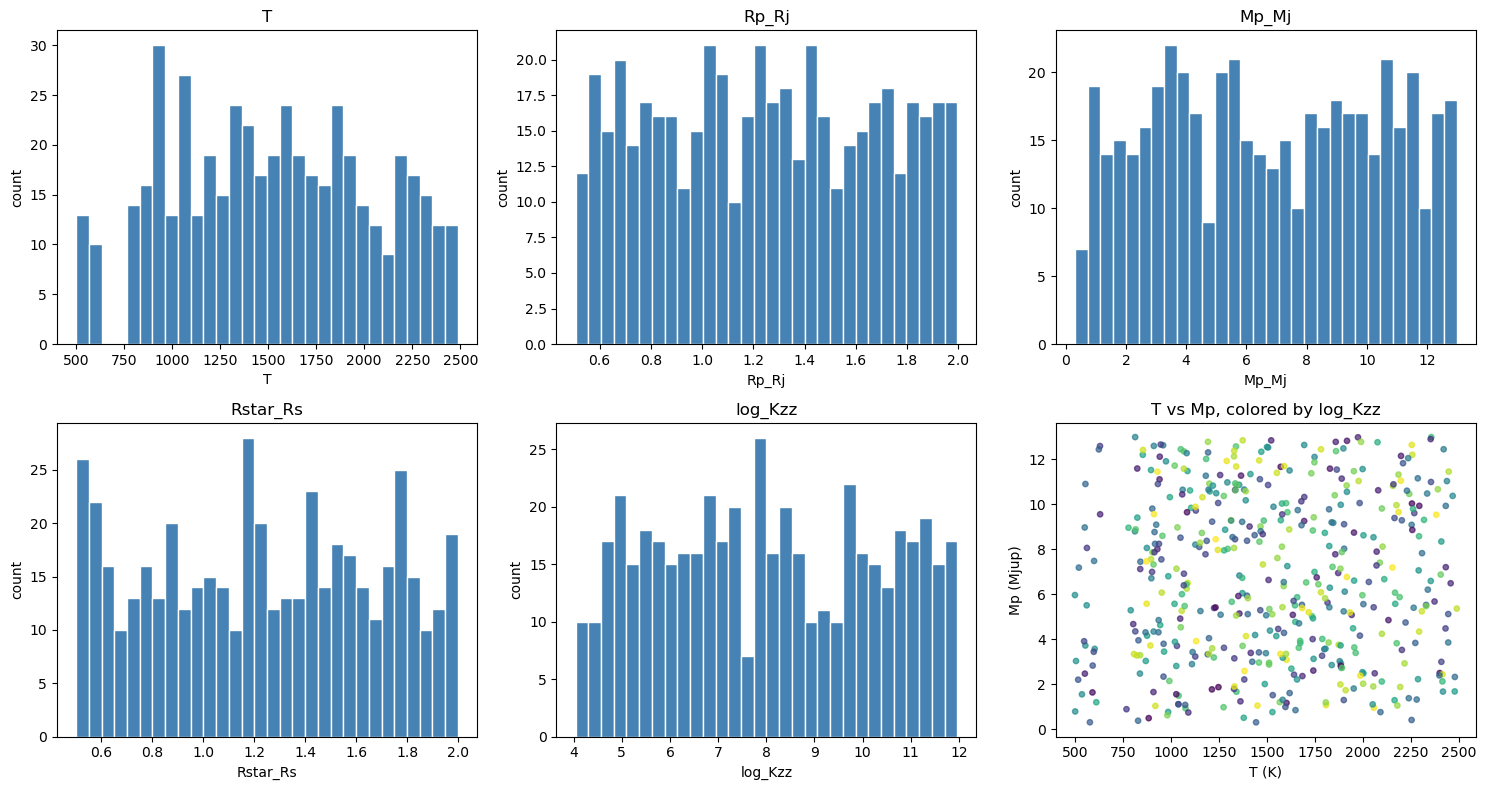

In [15]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

for ax, col in zip(axes, param_cols):
    ax.hist(df_final[col], bins=30, color="steelblue", edgecolor="white")
    ax.set_title(col)
    ax.set_xlabel(col)
    ax.set_ylabel("count")

# scatter to check for gaps/clustering in 2D param space
axes[5].scatter(df_final["T"], df_final["Mp_Mj"], c=df_final["log_Kzz"], cmap="viridis", s=15, alpha=0.7)
axes[5].set_xlabel("T (K)")
axes[5].set_ylabel("Mp (Mjup)")
axes[5].set_title("T vs Mp, colored by log_Kzz")

plt.tight_layout()
plt.show()

In [16]:
molecules = ["h2o", "ch4", "co", "co2", "nh3"]
issues = {mol: {"nan": 0, "inf": 0, "negative": 0, "gt_one": 0} for mol in molecules}

for path in df_final["path"]:
    d = np.load(path)
    for mol in molecules:
        arr = d[mol]
        issues[mol]["nan"] += np.isnan(arr).sum()
        issues[mol]["inf"] += np.isinf(arr).sum()
        issues[mol]["negative"] += (arr < 0).sum()
        issues[mol]["gt_one"] += (arr > 1).sum()

issues_df = pd.DataFrame(issues).T
print("VMR sanity issues across all profiles (counts of bad values, summed over all 100 layers x all profiles):")
print(issues_df)

VMR sanity issues across all profiles (counts of bad values, summed over all 100 layers x all profiles):
     nan  inf  negative  gt_one
h2o    0    0         0       0
ch4    0    0         0       0
co     0    0         0       0
co2    0    0         0       0
nh3    0    0         0       0


In [17]:
stats_rows = []
for mol in molecules:
    all_vals = np.concatenate([np.load(p)[mol] for p in df_final["path"]])
    stats_rows.append({
        "molecule": mol,
        "min": all_vals.min(),
        "max": all_vals.max(),
        "median": np.median(all_vals),
        "mean": all_vals.mean(),
    })

stats_df = pd.DataFrame(stats_rows)
print(stats_df)

  molecule           min       max        median          mean
0      h2o  1.442813e-06  0.001216  5.801374e-04  6.743788e-04
1      ch4  2.395196e-22  0.000592  4.491186e-05  1.851570e-04
2       co  1.000019e-50  0.000444  3.031537e-04  2.203813e-04
3      co2  1.000019e-50  0.000007  4.281805e-08  5.279647e-08
4      nh3  1.000206e-50  0.000124  4.506530e-06  3.140213e-05


In [18]:
flat_profile_flags = []

for path in df_final["path"]:
    d = np.load(path)
    is_flat = all(np.ptp(d[mol]) < 1e-12 for mol in molecules)  # ptp = max-min
    flat_profile_flags.append(is_flat)

df_final["is_flat"] = flat_profile_flags
n_flat = df_final["is_flat"].sum()
print(f"Profiles with near-zero variation across all 5 molecules (possible solver failure/no-op): {n_flat} / {len(df_final)}")

if n_flat > 0:
    print("\nBreakdown by account:")
    print(df_final[df_final["is_flat"]].groupby("account").size())

Profiles with near-zero variation across all 5 molecules (possible solver failure/no-op): 23 / 481

Breakdown by account:
account
acct2      10
acct3      10
unknown     3
dtype: int64


In [19]:
print("=" * 50)
print("EDA SUMMARY")
print("=" * 50)
print(f"Total unique VMR profiles: {len(df_final)}")
print(f"  acct1: {(df_final['account']=='acct1').sum()}")
print(f"  acct2: {(df_final['account']=='acct2').sum()}")
print(f"  acct3: {(df_final['account']=='acct3').sum()}")
print(f"  unknown (freckll_profiles_2): {(df_final['account']=='unknown').sum()}")
print(f"\nFlagged flat/degenerate profiles: {df_final['is_flat'].sum()}")
print(f"Profiles with any NaN/Inf/negative/out-of-range VMR: see Cell 12 output")
print(f"\nParameter space coverage: see Cell 10/11")

EDA SUMMARY
Total unique VMR profiles: 481
  acct1: 0
  acct2: 192
  acct3: 201
  unknown (freckll_profiles_2): 88

Flagged flat/degenerate profiles: 23
Profiles with any NaN/Inf/negative/out-of-range VMR: see Cell 12 output

Parameter space coverage: see Cell 10/11


In [23]:
import numpy as np

eq_full = np.load("equi_chem_data/eq_chemistry_full.npy", allow_pickle=True)
eq_params = np.load("equi_chem_data/eq_chemistry_params.npy", allow_pickle=True)
eq_spectra = np.load("equi_chem_data/eq_chemistry_spectra.npy", allow_pickle=True)
wl_binned = np.load("equi_chem_data/wl_binned.npy", allow_pickle=True)

for name, arr in [("eq_chemistry_full", eq_full), ("eq_chemistry_params", eq_params),
                   ("eq_chemistry_spectra", eq_spectra), ("wl_binned", wl_binned)]:
    print(f"{name}: shape={arr.shape}, dtype={arr.dtype}")

# Peek at structure — is eq_chemistry_params a structured array / dict-like / plain floats?
print("\neq_chemistry_params sample:")
print(eq_params[:3])

print("\neq_chemistry_full sample (first entry):")
print(eq_full[0] if eq_full.ndim == 1 else eq_full[0][:5])

eq_chemistry_full: shape=(113176, 58), dtype=float64
eq_chemistry_params: shape=(113176, 6), dtype=float64
eq_chemistry_spectra: shape=(113176, 52), dtype=float64
wl_binned: shape=(52,), dtype=float64

eq_chemistry_params sample:
[[ 7.34027961e-01  1.23745112e+00  7.89256662e-01  1.31125832e+03
   2.80285723e+00  1.51758910e+00]
 [ 5.30876741e-01  1.44533790e+00  4.84988025e+00  4.56825753e+02
   2.46470458e+00  1.28200702e+00]
 [ 9.56363364e-01  4.48468569e-01  2.62900984e+00  2.54759513e+03
  -1.50643557e-01  5.27284941e-01]]

eq_chemistry_full sample (first entry):
[0.03025624 0.03020096 0.03033303 0.03039215 0.03038761]


In [27]:
# Metadata table (params + file paths) — for reference/reproducibility
df_final.to_csv("df_final_metadata.csv", index=False)

# The actual VMR arrays, bundled together — this is what your spectra
# notebook (disequil_chem_spectra.ipynb) actually needs to load
import pickle
df_final.to_pickle("df_final.pkl")   # preserves dtypes, easiest to reload elsewhere
print("Saved df_final_metadata.csv and df_final.pkl")

Saved df_final_metadata.csv and df_final.pkl


In [28]:
df_final_clean = df_final[~df_final["is_flat"]].reset_index(drop=True)
print(f"Profiles after removing flat/degenerate: {len(df_final_clean)}")
print(df_final_clean.groupby("account").size())

Profiles after removing flat/degenerate: 458
account
acct2      182
acct3      191
unknown     85
dtype: int64


In [29]:
df_final_clean = df_final[~df_final["is_flat"]].reset_index(drop=True)
df_final_clean.to_csv("df_final_clean.csv", index=False)